# MW Scan Analysis (Hybrid LSQ + MLE Fit)

Run cells top-to-bottom. Same as analyze_mw_scan.ipynb but uses hybrid LSQ->MLE fitting with binomial likelihood.

In [34]:
# Setup (run once)
import sys, os
sys.path.insert(0, r"C:\Networking Experiment\Claude_TEST_faisal\useful_codes\repository")

import numpy as np
import matplotlib.pyplot as plt
import h5py
import glob
import datetime
from pathlib import Path

from analysis.data_loader import load_h5, find_runs, RESULTS_DIR
from analysis.microwave_analysis import fit_scan_result

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
print(f"Results directory: {RESULTS_DIR}")
print("Setup complete.")

Results directory: C:\Networking Experiment\Claude_TEST_faisal\useful_codes\repository\results
Setup complete.


## 1. List Recent Runs
Re-run this cell to refresh (e.g. after a new experiment finishes).

In [35]:
files = find_runs(format="h5")
if not files:
    print(f"No HDF5 files in {RESULTS_DIR}")
else:
    rows = []
    for f in files[-30:]:
        fname = os.path.basename(f)
        parts = fname.replace(".h5", "").split("-", 1)
        rid = parts[0] if parts else "?"
        exp = parts[1] if len(parts) > 1 else "?"
        folder = str(Path(f).parent.relative_to(RESULTS_DIR))
        dt = datetime.datetime.fromtimestamp(os.path.getmtime(f))
        mode = typ = ""
        try:
            with h5py.File(f, "r") as hf:
                ds = hf.get("datasets")
                if ds is not None:
                    for key in ["mw_scan_mode", "mw_scan_type"]:
                        if key in ds:
                            val = ds[key][()]
                            val = val.decode() if isinstance(val, bytes) else str(val)
                        elif key in ds.attrs:
                            val = ds.attrs[key]
                            val = val.decode() if isinstance(val, bytes) else str(val)
                        else:
                            val = ""
                        if key == "mw_scan_mode": mode = val
                        else: typ = val
        except Exception:
            pass
        rows.append((rid, exp, mode, typ, dt.strftime("%Y-%m-%d"), dt.strftime("%H:%M"), folder))

    print(f"{'RID':>9s}  {'Experiment':<22s}  {'Mode':<12s}  {'Type':<11s}  {'Date':<12s}  {'Time':<6s}  Folder")
    print(f"{'-'*9}  {'-'*22}  {'-'*12}  {'-'*11}  {'-'*12}  {'-'*6}  {'-'*20}")
    for r in reversed(rows):
        print(f"{r[0]:>9s}  {r[1]:<22s}  {r[2]:<12s}  {r[3]:<11s}  {r[4]:<12s}  {r[5]:<6s}  {r[6]}")

      RID  Experiment              Mode          Type         Date          Time    Folder
---------  ----------------------  ------------  -----------  ------------  ------  --------------------
000000098  MicrowaveScan           Freq_01       frequency    2026-04-06    11:13   2026-04-06\11
000000098  MicrowaveScan           Freq_01       frequency    2026-04-06    10:59   2026-04-06\10
000000095  MicrowaveScan           Freq_01       frequency    2026-04-06    10:36   2026-04-06\10
000000092  MicrowaveScan           Ramsey_00     ramsey       2026-04-06    01:47   2026-04-06\01
000000092  MicrowaveScan           Ramsey_00     ramsey       2026-04-06    00:59   2026-04-06\00
000000090  MicrowaveScan           Ramsey_00     ramsey       2026-04-05    23:52   2026-04-05\23
000000089  MicrowaveScan           Ramsey_00     ramsey       2026-04-05    23:26   2026-04-05\23
000000087  MicrowaveScan           Time_00       time         2026-04-05    22:59   2026-04-05\22
000000083  Microwave

## 2. Select Run
Set `RID` below and run the cell. Use `None` for the latest run.

In [36]:
########################################
RID = None   # <-- set RID here, or None for latest
########################################

if RID is not None:
    pattern = f"{RID:09d}-*.h5"
    matches = glob.glob(str(RESULTS_DIR / "**" / pattern), recursive=True)
    if not matches:
        raise FileNotFoundError(f"No HDF5 for RID {RID} in {RESULTS_DIR}")
    # Pick the latest file -- each incremental save has all data
    filepath = max(matches, key=os.path.getmtime)
    if len(matches) > 1:
        print("Found {} files for RID {}, using latest:".format(len(matches), RID))
        for m in sorted(matches, key=os.path.getmtime):
            sel = "<-- selected" if m == filepath else ""
            print("  {}  {} KB  {}".format(os.path.basename(m), int(os.path.getsize(m)/1024), sel))
else:
    all_files = find_runs(format="h5")
    if not all_files:
        raise FileNotFoundError(f"No HDF5 files in {RESULTS_DIR}")
    filepath = all_files[-1]
    print("(Using latest run)")

print(f"File: {os.path.basename(filepath)}")
print(f"Path: {filepath}")

result = load_h5(filepath)
data = result["data"]
meta = result["metadata"]
archive = result["archive"]

# Extract RID from filename (ARTIQ stores rid at top-level, not in datasets/)
try:
    run_rid = int(os.path.basename(filepath).split("-")[0])
except (ValueError, IndexError):
    run_rid = "?"
data["rid"] = run_rid
print(f"RID: {run_rid}")

## 3. Summary & Raw Data Table

In [37]:
for k, v in meta.items():
    val = v.decode() if isinstance(v, bytes) else v
    print(f"  {k}: {val}")

mode = data.get("mw_scan_mode", b"?")
if isinstance(mode, bytes): mode = mode.decode()
stype = data.get("mw_scan_type", b"?")
if isinstance(stype, bytes): stype = stype.decode()

if "mw_scan_x" in data:
    x_raw = np.asarray(data["mw_scan_x"], dtype=float)
    unique_x = np.unique(x_raw)
    n_pts = len(unique_x)
    n_total = len(x_raw)
    n_loops = n_total // max(n_pts, 1)
    print(f"\n  Mode: {mode}  |  Type: {stype}")
    print(f"  Scan points: {n_pts}  |  Loops: {n_loops}  |  Total: {n_total}")
    if stype == "frequency":
        print(f"  Range: {unique_x[0]/1e6:.4f} .. {unique_x[-1]/1e6:.4f} MHz")
    else:
        print(f"  Range: {unique_x[0]:.0f} .. {unique_x[-1]:.0f} mu")

    def avg_by_x(key):
        if key not in data: return None
        arr = np.asarray(data[key], dtype=float)
        return np.array([np.mean(arr[x_raw == xv]) for xv in unique_x]) if arr.size == x_raw.size else None

    # Retention = N(shot1>thresh AND shot2>thresh) / N(shot1>thresh)
    # Uses mw_atom_loaded and mw_atom_retained directly (works for old and new data)
    loaded_raw = np.asarray(data.get("mw_atom_loaded", []), dtype=float)
    retained_raw = np.asarray(data.get("mw_atom_retained", []), dtype=float)
    load_rate = avg_by_x("mw_atom_loaded")
    n_per = np.array([np.sum(x_raw == xv) for xv in unique_x])
    ret = np.zeros(len(unique_x))
    err = np.zeros(len(unique_x))
    n_loaded_per = np.zeros(len(unique_x), dtype=int)
    for i, xv in enumerate(unique_x):
        mask = x_raw == xv
        l = loaded_raw[mask] if loaded_raw.size == x_raw.size else np.zeros(mask.sum())
        r = retained_raw[mask] if retained_raw.size == x_raw.size else np.zeros(mask.sum())
        n_loaded = int(l.sum())
        n_retained = int((l * r).sum())
        n_loaded_per[i] = n_loaded
        if n_loaded > 0:
            ret[i] = n_retained / n_loaded
            err[i] = np.sqrt(max(ret[i]*(1-ret[i]), 0) / n_loaded)
        else:
            ret[i] = float('nan')
            err[i] = float('nan')

    s1 = avg_by_x("mw_shot1_spcm1"); s2 = avg_by_x("mw_shot1_spcm2")
    p1 = avg_by_x("mw_shot2_spcm1"); p2 = avg_by_x("mw_shot2_spcm2")
    b1 = avg_by_x("mw_bg_spcm1");    b2 = avg_by_x("mw_bg_spcm2")
    shot1_tot = (s1 + s2) if s1 is not None and s2 is not None else None
    shot2_tot = (p1 + p2) if p1 is not None and p2 is not None else None
    bg_tot = (b1 + b2) if b1 is not None and b2 is not None else None

    x_label = "Freq (MHz)" if stype == "frequency" else "Time (mu)"
    x_fmt = [f"{v/1e6:.4f}" for v in unique_x] if stype == "frequency" else [f"{v:.0f}" for v in unique_x]

    print(f"\n  {x_label:<14s}  {'N':>4s}  {'Nlod':>4s}  {'Ret':>6s}  {'Err':>6s}  {'Load':>5s}  {'Shot1':>6s}  {'Shot2':>6s}  {'BG':>5s}")
    print(f"  {'-'*14}  {'-'*4}  {'-'*4}  {'-'*6}  {'-'*6}  {'-'*5}  {'-'*6}  {'-'*6}  {'-'*5}")
    for i in range(len(unique_x)):
        row = f"  {x_fmt[i]:<14s}  {int(n_per[i]):>4d}  {n_loaded_per[i]:>4d}"
        row += f"  {ret[i]:>6.3f}" if not np.isnan(ret[i]) else "     --"
        row += f"  {err[i]:>6.3f}" if not np.isnan(err[i]) else "     --"
        row += f"  {load_rate[i]:>5.2f}" if load_rate is not None else "      "
        row += f"  {shot1_tot[i]:>6.1f}" if shot1_tot is not None else "       "
        row += f"  {shot2_tot[i]:>6.1f}" if shot2_tot is not None else "       "
        row += f"  {bg_tot[i]:>5.1f}" if bg_tot is not None else "      "
        print(row)
else:
    print("\nNo MW scan data in this file.")
    print("Datasets:", sorted(data.keys()))

  experiment: MicrowaveScan
  feedback_profile: low_FORT
  hostname: DESKTOP-J6651GV
  rid: 98
  start_time: 2026-04-06T11:13:53.392393

  Mode: Freq_01  |  Type: frequency
  Scan points: 16  |  Loops: 100  |  Total: 1600
  Range: 250.4600 .. 250.5200 MHz

  Freq (MHz)         N  Nlod     Ret     Err   Load   Shot1   Shot2     BG
  --------------  ----  ----  ------  ------  -----  ------  ------  -----
  250.4600         100    51   0.882   0.045   0.51    22.9    20.8    5.9
  250.4640         100    53   0.830   0.052   0.53    23.6    21.3    6.5
  250.4680         100    57   0.632   0.064   0.57    25.3    17.9    6.1
  250.4720         100    46   0.413   0.073   0.46    21.4    12.8    6.1
  250.4760         100    48   0.375   0.070   0.48    22.1    10.9    6.5
  250.4800         100    60   0.183   0.050   0.60    26.5     8.4    5.8
  250.4840         100    50   0.120   0.046   0.50    22.4     6.2    6.2
  250.4880         100    54   0.056   0.031   0.54    23.3     5.0 

## 4. Plot Retention + Counts
Re-run this cell to refresh after more data is collected (incremental saves).

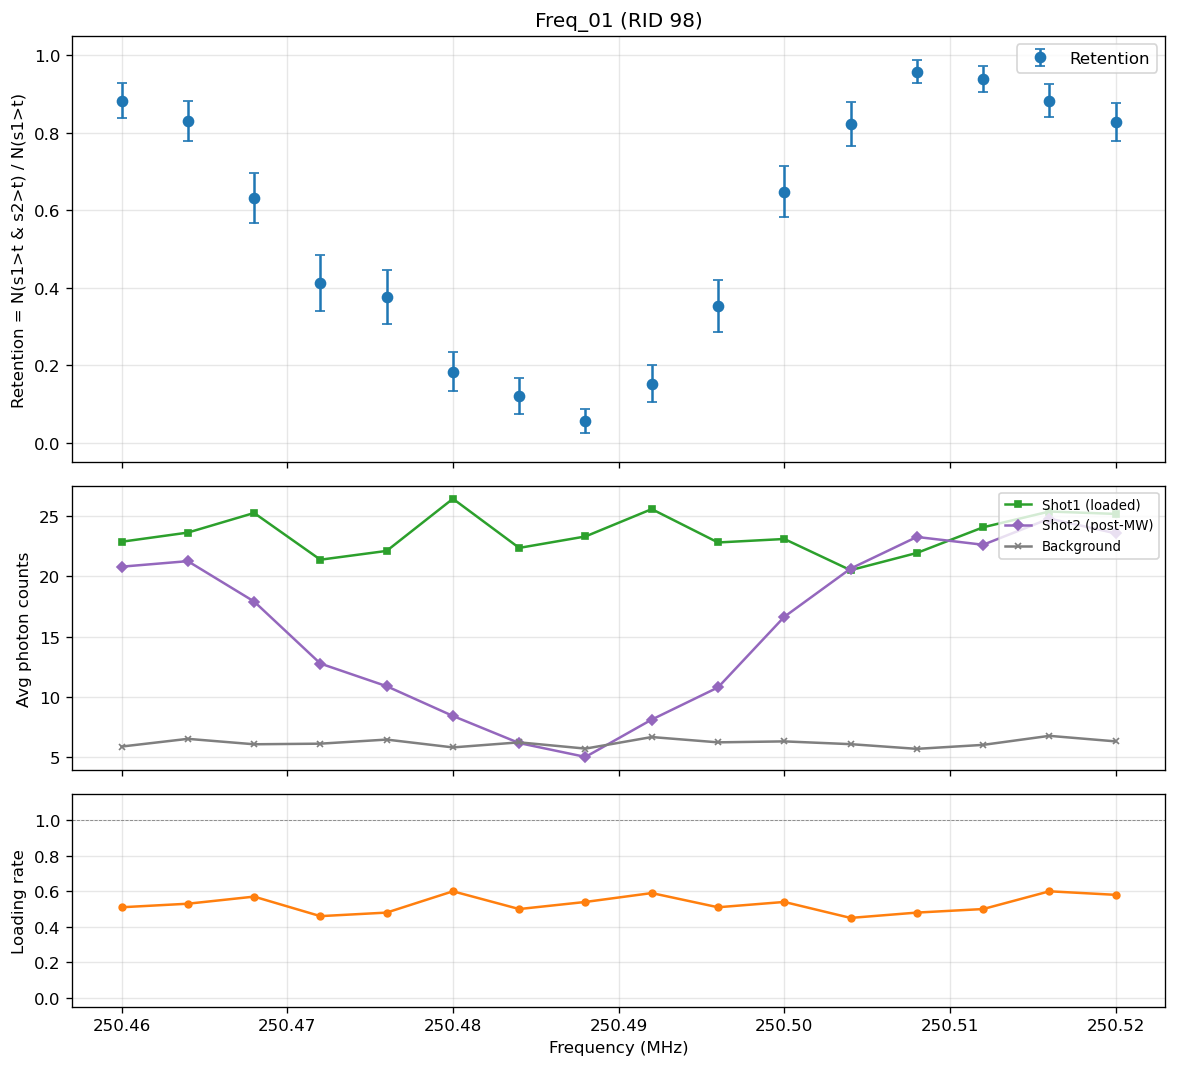

Total: 1600 shots, 100 loops


In [38]:
# Reload data (picks up incremental saves)
result = load_h5(filepath)
data = result["data"]

x_raw = np.asarray(data["mw_scan_x"], dtype=float)
unique_x = np.unique(x_raw)
loaded_raw = np.asarray(data.get("mw_atom_loaded", []), dtype=float)
retained_raw = np.asarray(data.get("mw_atom_retained", []), dtype=float)

def avg_by_x(key):
    if key not in data: return None
    arr = np.asarray(data[key], dtype=float)
    return np.array([np.mean(arr[x_raw == xv]) for xv in unique_x]) if arr.size == x_raw.size else None

stype = data.get("mw_scan_type", b"frequency")
if isinstance(stype, bytes): stype = stype.decode()
mode = data.get("mw_scan_mode", b"MW Scan")
if isinstance(mode, bytes): mode = mode.decode()

if stype == "frequency":
    xp = unique_x / 1e6
    xlabel = "Frequency (MHz)"
else:
    xp = unique_x
    xlabel = "Duration (mu)" if stype == "time" else "Free evolution (mu)"

# Retention = N(shot1>thresh AND shot2>thresh) / N(shot1>thresh)
ret = np.zeros(len(unique_x))
err = np.zeros(len(unique_x))
for i, xv in enumerate(unique_x):
    mask = x_raw == xv
    l = loaded_raw[mask] if loaded_raw.size == x_raw.size else np.zeros(mask.sum())
    r = retained_raw[mask] if retained_raw.size == x_raw.size else np.zeros(mask.sum())
    n_loaded = int(l.sum())
    n_retained = int((l * r).sum())
    if n_loaded > 0:
        ret[i] = n_retained / n_loaded
        err[i] = np.sqrt(max(ret[i]*(1-ret[i]), 0) / n_loaded)
    else:
        ret[i] = float('nan')
        err[i] = float('nan')
load_rate = avg_by_x("mw_atom_loaded")

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [3, 2, 1.5]})

ax1 = axes[0]
valid_mask = ~np.isnan(ret)
if valid_mask.any():
    ax1.errorbar(xp[valid_mask], ret[valid_mask], yerr=err[valid_mask],
                 fmt="o", color="C0", capsize=3, markersize=6, label="Retention")
ax1.set_ylabel("Retention = N(s1>t & s2>t) / N(s1>t)")
ax1.set_ylim(-0.05, 1.05)
ax1.legend(loc="upper right")
ax1.grid(True, alpha=0.3)
#ax1.set_title(f"{mode} (RID {data.get('rid', '?')})")
ax1.set_title(f"{mode} (RID {run_rid})")

ax2 = axes[1]
s1 = avg_by_x("mw_shot1_spcm1"); s2 = avg_by_x("mw_shot1_spcm2")
p1 = avg_by_x("mw_shot2_spcm1"); p2 = avg_by_x("mw_shot2_spcm2")
b1 = avg_by_x("mw_bg_spcm1");    b2 = avg_by_x("mw_bg_spcm2")
if s1 is not None and s2 is not None:
    ax2.plot(xp, s1+s2, "s-", color="C2", ms=4, label="Shot1 (loaded)")
if p1 is not None and p2 is not None:
    ax2.plot(xp, p1+p2, "D-", color="C4", ms=4, label="Shot2 (post-MW)")
if b1 is not None and b2 is not None:
    ax2.plot(xp, b1+b2, "x-", color="C7", ms=4, label="Background")
ax2.set_ylabel("Avg photon counts")
ax2.legend(fontsize=8, loc="upper right")
ax2.grid(True, alpha=0.3)

ax3 = axes[2]
if load_rate is not None:
    ax3.plot(xp, load_rate, "o-", color="C1", ms=4)
    ax3.axhline(1.0, color="gray", ls="--", lw=0.5)
ax3.set_ylabel("Loading rate")
ax3.set_ylim(-0.05, 1.15)
ax3.set_xlabel(xlabel)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f"Total: {len(x_raw)} shots, {len(x_raw)//max(len(unique_x),1)} loops")

## 5. Hybrid Fit (LSQ -> MLE)
LSQ for initial guess, then MLE refinement with binomial negative log-likelihood using raw k/n counts per scan point.

In [39]:
########################################
EXCLUDE_LEFT = 0    # number of points to exclude from the left edge
EXCLUDE_RIGHT = 0   # number of points to exclude from the right edge

# Manual initial guess override (set to None for auto, or provide list)
# Frequency: [A, x0_MHz, sigma_MHz, y0]       e.g. [-0.8, 250.49, 0.01, 0.9]
# Rabi:      [A, f, phi, tau, y0]              e.g. [0.4, 0.00011, 0, 500000, 0.5]
# Ramsey:    [A, f_kHz, phi, tau_ms, y0, n]    e.g. [0.4, 4.3, 0, 13, 0.5, 2.0]
MANUAL_P0 = None

# Manual bounds override (set to None for auto, or provide (lo_list, hi_list))
# Same parameter order as MANUAL_P0 above
# e.g. for Ramsey: MANUAL_BOUNDS = ([0, 1, -6.28, 1, 0, 1], [1, 20, 6.28, 1e6, 1, 2])
MANUAL_BOUNDS = None
########################################

fit_result = None
fitter = None
valid = ~np.isnan(ret)

# Exclude edge points
valid_indices = np.where(valid)[0]
if EXCLUDE_LEFT > 0 and len(valid_indices) > EXCLUDE_LEFT:
    for idx in valid_indices[:EXCLUDE_LEFT]:
        valid[idx] = False
if EXCLUDE_RIGHT > 0 and len(valid_indices) > EXCLUDE_RIGHT:
    for idx in valid_indices[-EXCLUDE_RIGHT:]:
        valid[idx] = False

if EXCLUDE_LEFT > 0 or EXCLUDE_RIGHT > 0:
    print(f"Excluded {EXCLUDE_LEFT} left + {EXCLUDE_RIGHT} right -> {valid.sum()} points for fit")

if valid.sum() >= 3:
    x_fit = unique_x[valid]
    ret_fit = ret[valid]
    err_fit = err[valid].copy()
    err_fit[err_fit == 0] = 0.01

    # Compute k (retained) and n (loaded) per scan point for MLE
    k_fit = np.zeros(valid.sum())
    n_fit = np.zeros(valid.sum())
    j = 0
    for i_kn, xv_kn in enumerate(unique_x):
        if not valid[i_kn]: continue
        mask = x_raw == xv_kn
        l_kn = loaded_raw[mask] if loaded_raw.size == x_raw.size else np.zeros(mask.sum())
        r_kn = retained_raw[mask] if retained_raw.size == x_raw.size else np.zeros(mask.sum())
        n_fit[j] = int(l_kn.sum())
        k_fit[j] = int((l_kn * r_kn).sum())
        j += 1

    print(f"Fitting {valid.sum()} points:")
    for j in range(len(x_fit)):
        xv = x_fit[j] / 1e6 if stype == "frequency" else x_fit[j]
        print(f"  x={xv:.4f}  ret={ret_fit[j]:.3f}  err={err_fit[j]:.3f}")

    if stype == "frequency":
        from fitting.gaussian_dip import GaussianDipFit
        fitter = GaussianDipFit()
        x_mhz = x_fit / 1e6
        x_all_mhz = unique_x[~np.isnan(ret)] / 1e6

        if MANUAL_P0 is not None:
            p0 = list(MANUAL_P0)
            A_lo = -2.0 if p0[0] < 0 else -0.01
            A_hi = 0.01 if p0[0] < 0 else 2.0
            print(f"  Using MANUAL p0: {p0}")
        else:
            idx_min = np.argmin(ret_fit)
            idx_max = np.argmax(ret_fit)
            y_median = np.median(ret_fit)
            dip_depth = abs(ret_fit[idx_min] - y_median)
            peak_height = abs(ret_fit[idx_max] - y_median)
            if peak_height > dip_depth:
                y0_guess = min(ret_fit[0], ret_fit[-1], y_median)
                A_guess = ret_fit[idx_max] - y0_guess
                x0_guess = x_mhz[idx_max]
                A_lo, A_hi = -0.01, 2.0
                print("  Detected: PEAK")
            else:
                y0_guess = max(ret_fit[0], ret_fit[-1], y_median)
                A_guess = ret_fit[idx_min] - y0_guess
                x0_guess = x_mhz[idx_min]
                A_lo, A_hi = -2.0, 0.01
                print("  Detected: DIP")
            sigma_guess = (x_mhz[-1] - x_mhz[0]) / 6.0
            p0 = [A_guess, x0_guess, sigma_guess, y0_guess]

        if MANUAL_BOUNDS is not None:
            bounds = (list(MANUAL_BOUNDS[0]), list(MANUAL_BOUNDS[1]))
            print(f"  Using MANUAL bounds")
        else:
            bounds = (
                [A_lo, x_all_mhz[0], 1e-6, -0.5],
                [A_hi, x_all_mhz[-1], x_all_mhz[-1] - x_all_mhz[0], 2.0]
            )
        print(f"  p0: {[round(v,4) for v in p0]}")
        print(f"  lo: {[round(v,4) for v in bounds[0]]}")
        print(f"  hi: {[round(v,4) for v in bounds[1]]}")

        mle_bounds = list(zip(bounds[0], bounds[1]))
        fit_res = fitter.fit_hybrid(x_mhz, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, lsq_bounds=bounds, mle_bounds=mle_bounds, p0=p0)
        if fit_res["success"]:
            center, center_err = fitter.center(fit_res)
            fwhm, fwhm_err = fitter.fwhm(fit_res)
            print(f"\nFIT SUCCEEDED")
            print(f"  Resonance: {center:.6f} +/- {center_err:.6f} MHz")
            print(f"  FWHM: {fwhm:.6f} +/- {fwhm_err:.6f} MHz")
            fit_result = fit_res
        else:
            print("\nFIT FAILED (see error above)")

    elif stype == "ramsey":
        from fitting.damped_cosine import RamseyFit
        fitter = RamseyFit()
        x_ms = x_fit / 1e6
        print(f"  Ramsey: x -> ms, range {x_ms[0]:.2f} - {x_ms[-1]:.2f} ms")
        if MANUAL_P0 is not None:
            p0 = list(MANUAL_P0)
            print(f"  Using MANUAL p0: {p0}")
            if MANUAL_BOUNDS is not None:
                bounds = (list(MANUAL_BOUNDS[0]), list(MANUAL_BOUNDS[1]))
                print(f"  Using MANUAL bounds")
                mle_b_r = list(zip(bounds[0], bounds[1]))
                fit_res = fitter.fit_hybrid(x_ms, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, lsq_bounds=bounds, mle_bounds=mle_b_r, p0=p0)
            else:
                _, lo_r, hi_r = fitter.initial_guess(x_ms, ret_fit, yerr=err_fit)
                mle_b_r = list(zip(lo_r, hi_r))
                fit_res = fitter.fit_hybrid(x_ms, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, mle_bounds=mle_b_r, p0=p0)
        else:
            if MANUAL_BOUNDS is not None:
                p0_auto, _, _ = fitter.initial_guess(x_ms, ret_fit, yerr=err_fit)
                bounds = (list(MANUAL_BOUNDS[0]), list(MANUAL_BOUNDS[1]))
                print(f"  Using MANUAL bounds")
                mle_b_r = list(zip(bounds[0], bounds[1]))
                fit_res = fitter.fit_hybrid(x_ms, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, lsq_bounds=bounds, mle_bounds=mle_b_r, p0=p0_auto)
            else:
                _, lo_r, hi_r = fitter.initial_guess(x_ms, ret_fit, yerr=err_fit)
                mle_b_r = list(zip(lo_r, hi_r))
                fit_res = fitter.fit_hybrid(x_ms, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, mle_bounds=mle_b_r)
        if fit_res["success"]:
            f_khz, f_err = fitter.frequency_khz(fit_res)
            tau_ms, tau_err = fitter.decay_time_ms(fit_res)
            n_exp, n_err = fitter.decay_exponent(fit_res)
            vis, vis_err = fitter.visibility(fit_res)
            print(f"\nFIT SUCCEEDED")
            print(f"  Frequency: {f_khz:.4f} +/- {f_err:.4f} kHz")
            print(f"  Tau: {tau_ms:.2f} +/- {tau_err:.2f} ms")
            print(f"  Exponent n: {n_exp:.2f} +/- {n_err:.2f}")
            print(f"  Visibility: {vis:.3f} +/- {vis_err:.3f}")
            fit_result = fit_res
        else:
            print("\nFIT FAILED (see error above)")

    elif stype == "time":
        from fitting.damped_cosine import RabiFit
        fitter = RabiFit()
        if MANUAL_P0 is not None:
            p0 = list(MANUAL_P0)
            print(f"  Using MANUAL p0: {p0}")
            if MANUAL_BOUNDS is not None:
                bounds = (list(MANUAL_BOUNDS[0]), list(MANUAL_BOUNDS[1]))
                print(f"  Using MANUAL bounds")
                mle_b_t = list(zip(bounds[0], bounds[1]))
                fit_res = fitter.fit_hybrid(x_fit, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, lsq_bounds=bounds, mle_bounds=mle_b_t, p0=p0)
            else:
                _, lo_t, hi_t = fitter.initial_guess(x_fit, ret_fit, yerr=err_fit)
                mle_b_t = list(zip(lo_t, hi_t))
                fit_res = fitter.fit_hybrid(x_fit, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, mle_bounds=mle_b_t, p0=p0)
        else:
            if MANUAL_BOUNDS is not None:
                p0_auto, _, _ = fitter.initial_guess(x_fit, ret_fit, yerr=err_fit)
                bounds = (list(MANUAL_BOUNDS[0]), list(MANUAL_BOUNDS[1]))
                print(f"  Using MANUAL bounds")
                mle_b_t = list(zip(bounds[0], bounds[1]))
                fit_res = fitter.fit_hybrid(x_fit, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, lsq_bounds=bounds, mle_bounds=mle_b_t, p0=p0_auto)
            else:
                _, lo_t, hi_t = fitter.initial_guess(x_fit, ret_fit, yerr=err_fit)
                mle_b_t = list(zip(lo_t, hi_t))
                fit_res = fitter.fit_hybrid(x_fit, ret_fit, yerr=err_fit, k=k_fit, n=n_fit, mle_bounds=mle_b_t)
        if fit_res["success"]:
            pd = fitter.param_dict(fit_res)
            print(f"\nFIT SUCCEEDED")
            print(f"  Pi time: {fitter.pi_time(fit_res):.0f} mu")
            print(f"  f = {pd['f']['value']:.6f} +/- {pd['f']['error']:.6f}")
            fit_result = fit_res
        else:
            print("\nFIT FAILED (see error above)")
    else:
        print(f"No fitter for type '{stype}'")
else:
    print(f"Cannot fit: {valid.sum()} valid points (need >= 3)")

# Plot ALL data + fit overlay
fig, ax = plt.subplots(figsize=(10, 5))
all_valid = ~np.isnan(ret)
if all_valid.any():
    excluded = all_valid & ~valid
    if stype == "ramsey":
        xp_v = xp[valid] / 1e6
        xp_e = xp[excluded] / 1e6 if excluded.any() else np.array([])
        fit_xlabel = "Free evolution time (ms)"
    elif stype == "frequency":
        xp_v = xp[valid]
        xp_e = xp[excluded] if excluded.any() else np.array([])
        fit_xlabel = "Frequency (MHz)"
    else:
        xp_v = xp[valid]
        xp_e = xp[excluded] if excluded.any() else np.array([])
        fit_xlabel = "Duration (mu)"
    ax.errorbar(xp_v, ret[valid], yerr=err[valid], fmt="o", color="C0",
                capsize=3, ms=6, label="Data (fitted)")
    if excluded.any():
        ax.errorbar(xp_e, ret[excluded], yerr=err[excluded], fmt="o", color="gray",
                    capsize=3, ms=5, alpha=0.4, label="Excluded")

if fit_result and fit_result.get("success") and fitter is not None:
    if stype == "ramsey":
        x_fine_fit = np.linspace(unique_x[all_valid].min() / 1e6, unique_x[all_valid].max() / 1e6, 2000)
    elif stype == "frequency":
        x_fine_fit = np.linspace(unique_x[all_valid].min() / 1e6, unique_x[all_valid].max() / 1e6, 500)
    else:
        x_fine_fit = np.linspace(unique_x[all_valid].min(), unique_x[all_valid].max(), 500)
    y_fine = fitter.evaluate(x_fine_fit, fit_result["params"])
    ax.plot(x_fine_fit, y_fine, "r-", lw=1.5, alpha=0.8, label="Fit")
else:
    fit_xlabel = xlabel

ax.set_xlabel(fit_xlabel)
ax.set_ylabel("Retention P(retained | loaded)")
ax.set_ylim(-0.05, 1.05)
ax.set_title(f"{mode} (RID {run_rid}) - Fit")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5c. LSQ vs Hybrid MLE Comparison
Run both methods on the same data and compare parameters, errors, and goodness-of-fit.

In [40]:
# Side-by-side LSQ vs Hybrid MLE comparison with Bootstrap errors
from fitting.gaussian_dip import GaussianDipFit
from fitting.damped_cosine import RabiFit, RamseyFit

N_BOOTSTRAP = 1000  # number of bootstrap iterations

valid_cmp = ~np.isnan(ret)
# Apply same exclusion as cell 5
vi = np.where(valid_cmp)[0]
if EXCLUDE_LEFT > 0 and len(vi) > EXCLUDE_LEFT:
    for idx in vi[:EXCLUDE_LEFT]: valid_cmp[idx] = False
if EXCLUDE_RIGHT > 0 and len(vi) > EXCLUDE_RIGHT:
    for idx in vi[-EXCLUDE_RIGHT:]: valid_cmp[idx] = False

x_c = unique_x[valid_cmp]
ret_c = ret[valid_cmp]
err_c = err[valid_cmp].copy()
err_c[err_c == 0] = 0.01

# Build k, n arrays AND store per-shot binary outcomes for bootstrap
k_c = np.zeros(valid_cmp.sum())
n_c = np.zeros(valid_cmp.sum())
per_shot_outcomes = []  # list of arrays: 1=retained, 0=not retained (only loaded shots)
j = 0
for i, xv_i in enumerate(unique_x):
    if not valid_cmp[i]: continue
    mask = x_raw == xv_i
    l = loaded_raw[mask] if loaded_raw.size == x_raw.size else np.zeros(mask.sum())
    r_i = retained_raw[mask] if retained_raw.size == x_raw.size else np.zeros(mask.sum())
    loaded_mask = l > 0
    n_c[j] = int(l.sum())
    k_c[j] = int((l * r_i).sum())
    per_shot_outcomes.append(r_i[loaded_mask].astype(int))  # binary array for loaded shots
    j += 1

# Select fitter
if stype == "frequency":
    fitter_cmp = GaussianDipFit()
    x_f = x_c / 1e6
elif stype == "ramsey":
    fitter_cmp = RamseyFit()
    x_f = x_c
else:
    fitter_cmp = RabiFit()
    x_f = x_c

# Initial guess and bounds
if stype == "frequency":
    x_all_f = unique_x[~np.isnan(ret)] / 1e6
    idx_min_c = np.argmin(ret_c)
    idx_max_c = np.argmax(ret_c)
    y_med = np.median(ret_c)
    if abs(ret_c[idx_max_c] - y_med) > abs(ret_c[idx_min_c] - y_med):
        y0_g = min(ret_c[0], ret_c[-1], y_med)
        A_g = ret_c[idx_max_c] - y0_g
        x0_g = x_f[idx_max_c]
        A_lo_c, A_hi_c = -0.01, 2.0
    else:
        y0_g = max(ret_c[0], ret_c[-1], y_med)
        A_g = ret_c[idx_min_c] - y0_g
        x0_g = x_f[idx_min_c]
        A_lo_c, A_hi_c = -2.0, 0.01
    sig_g = (x_f[-1] - x_f[0]) / 6.0
    p0_cmp = [A_g, x0_g, sig_g, y0_g]
    lsq_bounds_cmp = ([A_lo_c, x_all_f[0], 1e-6, -0.5], [A_hi_c, x_all_f[-1], x_all_f[-1]-x_all_f[0], 2.0])
    mle_bounds = list(zip(lsq_bounds_cmp[0], lsq_bounds_cmp[1]))
    res_lsq = fitter_cmp.fit_lsq(x_f, ret_c, yerr=err_c, p0=p0_cmp, bounds=lsq_bounds_cmp)
    res_hyb = fitter_cmp.fit_hybrid(x_f, ret_c, yerr=err_c, k=k_c, n=n_c, lsq_bounds=lsq_bounds_cmp, mle_bounds=mle_bounds, p0=p0_cmp)
else:
    # Time/Ramsey: use fitter own initial_guess
    p0_auto, lo, hi = fitter_cmp.initial_guess(x_f, ret_c, yerr=err_c)
    lsq_bounds_cmp = (lo, hi)
    mle_bounds = list(zip(lo, hi))
    res_lsq = fitter_cmp.fit_lsq(x_f, ret_c, yerr=err_c)
    res_hyb = fitter_cmp.fit_hybrid(x_f, ret_c, yerr=err_c, k=k_c, n=n_c, mle_bounds=mle_bounds)

# --- Bootstrap MLE errors ---
print(f"Running {N_BOOTSTRAP} bootstrap iterations...", end=" ", flush=True)
boot_params = []
rng = np.random.default_rng(42)

for b in range(N_BOOTSTRAP):
    # Resample per-shot binary outcomes at each scan point
    k_boot = np.zeros(len(x_f))
    n_boot = np.zeros(len(x_f))
    for s in range(len(x_f)):
        outcomes = per_shot_outcomes[s]
        if len(outcomes) == 0:
            n_boot[s] = 0
            k_boot[s] = 0
            continue
        resampled = rng.choice(outcomes, size=len(outcomes), replace=True)
        n_boot[s] = len(resampled)
        k_boot[s] = resampled.sum()

    # Recompute retention for LSQ initial guess
    ret_boot = np.array([k_boot[s] / max(n_boot[s], 1) for s in range(len(x_f))])

    # Run MLE with original params as starting point
    p0_boot = res_hyb["params"] if res_hyb["success"] else res_lsq["params"]
    mle_boot = fitter_cmp.fit_mle_binomial(x_f, k_boot, n_boot, p0=p0_boot, bounds=mle_bounds)
    if mle_boot["success"]:
        boot_params.append(mle_boot["params"])

boot_params = np.array(boot_params)
n_success = len(boot_params)
print(f"{n_success}/{N_BOOTSTRAP} converged")

if n_success > 10:
    boot_mean = boot_params.mean(axis=0)
    boot_std = boot_params.std(axis=0)
else:
    boot_mean = res_hyb["params"] if res_hyb["success"] else res_lsq["params"]
    boot_std = np.full(len(boot_mean), float('nan'))

# --- R^2 ---
if res_lsq["success"]:
    y_lsq = fitter_cmp.evaluate(x_f, res_lsq["params"])
    ss_res_lsq = np.sum((ret_c - y_lsq)**2)
    ss_tot = np.sum((ret_c - ret_c.mean())**2)
    r2_lsq = 1 - ss_res_lsq / ss_tot if ss_tot > 0 else 0
else:
    r2_lsq = float('nan')
r2_hyb = res_hyb.get("r_squared", float('nan'))

# --- BIC ---
n_data = len(x_f)
n_params = len(fitter_cmp.param_names)
if res_lsq["success"]:
    bic_lsq = n_data * np.log(ss_res_lsq / n_data) + n_params * np.log(n_data)
else:
    bic_lsq = float('nan')
if res_hyb["success"]:
    y_hyb = fitter_cmp.evaluate(x_f, res_hyb["params"])
    rss_hyb = np.sum((ret_c - y_hyb)**2)
    bic_hyb = n_data * np.log(rss_hyb / n_data) + n_params * np.log(n_data)
    nll = res_hyb.get("nll", None)
else:
    bic_hyb = float('nan')
    nll = None

# --- Print comparison table ---
print(f"\n{'':20s}  {'LSQ':>16s}  {'MLE (Hessian)':>16s}  {'MLE (Bootstrap)':>16s}")
print(f"{'-'*20}  {'-'*16}  {'-'*16}  {'-'*16}")
for pi, pname in enumerate(fitter_cmp.param_names):
    v1 = f"{res_lsq['params'][pi]:.6f}" if res_lsq["success"] else "---"
    e1 = f"{res_lsq['errors'][pi]:.6f}" if res_lsq["success"] else "---"
    v2 = f"{res_hyb['params'][pi]:.6f}" if res_hyb["success"] else "---"
    e2 = f"{res_hyb['errors'][pi]:.6f}" if res_hyb["success"] else "---"
    v3 = f"{boot_mean[pi]:.6f}" if not np.isnan(boot_std[pi]) else "---"
    e3 = f"{boot_std[pi]:.6f}" if not np.isnan(boot_std[pi]) else "---"
    print(f"{pname:>20s}  {v1:>16s}  {v2:>16s}  {v3:>16s}")
    print(f"{'+/- ' + pname:>20s}  {e1:>16s}  {e2:>16s}  {e3:>16s}")
print(f"{'-'*20}  {'-'*16}  {'-'*16}  {'-'*16}")
print(f"{'R^2':>20s}  {r2_lsq:>16.6f}  {r2_hyb:>16.6f}  {'':>16s}")
print(f"{'BIC':>20s}  {bic_lsq:>16.4f}  {bic_hyb:>16.4f}  {'':>16s}")
if nll is not None:
    print(f"{'NLL (binomial)':>20s}  {'N/A':>16s}  {nll:>16.4f}  {'':>16s}")

if not np.isnan(bic_lsq) and not np.isnan(bic_hyb):
    better = "Hybrid MLE" if bic_hyb < bic_lsq else "LSQ"
    print(f"\nBIC favors: {better}")

# --- Plot fits overlaid ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
xp_c = x_c / 1e6 if stype == "frequency" else x_c
ax.errorbar(xp_c, ret_c, yerr=err_c, fmt="o", color="C0", capsize=3, ms=6, label="Data")
x_fine = np.linspace(x_f.min(), x_f.max(), 500)
if res_lsq["success"]:
    ax.plot(x_fine, fitter_cmp.evaluate(x_fine, res_lsq["params"]),
            "b--", lw=1.5, alpha=0.7, label=f"LSQ (R^2={r2_lsq:.4f})")
if res_hyb["success"]:
    ax.plot(x_fine, fitter_cmp.evaluate(x_fine, res_hyb["params"]),
            "r-", lw=2, alpha=0.8, label=f"MLE (R^2={r2_hyb:.4f})")
ax.set_xlabel(xlabel)
ax.set_ylabel("Retention")
ax.set_ylim(-0.05, 1.05)
    ax.set_title("RID {} - LSQ vs MLE".format(run_rid))
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# --- Bootstrap parameter histograms ---
ax2 = axes[1]
if n_success > 10:
    # Show histogram for the most important parameter (x0 for frequency, f for time)
    if stype == "frequency":
        param_idx = 1  # x0 (center)
        param_label = "Center (MHz)"
    else:
        param_idx = 1  # f (frequency)
        param_label = "Frequency"

    ax2.hist(boot_params[:, param_idx], bins=40, color="C3", alpha=0.7, edgecolor="black", lw=0.5)
    ax2.axvline(boot_mean[param_idx], color="r", lw=2, label=f"MLE boot: {boot_mean[param_idx]:.6f} +/- {boot_std[param_idx]:.6f}")
    if res_lsq["success"]:
        ax2.axvline(res_lsq["params"][param_idx], color="b", ls="--", lw=1.5,
                    label=f"LSQ: {res_lsq['params'][param_idx]:.6f} +/- {res_lsq['errors'][param_idx]:.6f}")
    ax2.set_xlabel(param_label)
    ax2.set_ylabel("Bootstrap counts")
    ax2.set_title(f"Bootstrap distribution (N={n_success})")
    ax2.legend(fontsize=7)
else:
    ax2.text(0.5, 0.5, "Too few bootstrap successes", transform=ax2.transAxes, ha="center")

plt.tight_layout()
plt.show()


## 5b. Ramsey Segment Zoom
Plot each Ramsey segment separately for closer inspection. Auto-detects segments from gaps in the scan axis.

In [ ]:
# Auto-detect segments from gaps in scan axis (works for Ramsey multi-segment scans)
valid_mask = ~np.isnan(ret)

# Use ms for Ramsey, MHz for frequency, mu for time
if stype == "ramsey":
    xv_seg = unique_x[valid_mask] / 1e6  # mu to ms
    seg_unit = "ms"
elif stype == "frequency":
    xv_seg = unique_x[valid_mask] / 1e6  # Hz to MHz
    seg_unit = "MHz"
else:
    xv_seg = unique_x[valid_mask]
    seg_unit = "mu"

rv = ret[valid_mask]
ev = err[valid_mask]

# Find segment boundaries: gap > 2x median step
if len(xv_seg) > 1:
    diffs = np.diff(xv_seg)
    median_step = np.median(diffs)
    gap_indices = np.where(diffs > 2 * median_step)[0]
    seg_starts = np.concatenate([[0], gap_indices + 1])
    seg_ends = np.concatenate([gap_indices + 1, [len(xv_seg)]])
else:
    seg_starts = [0]
    seg_ends = [len(xv_seg)]

n_segs = len(seg_starts)
print("Found %d segment(s)" % n_segs)

if n_segs > 1:
    fig, axes = plt.subplots(1, n_segs, figsize=(5 * n_segs, 4), sharey=True)
    if n_segs == 1:
        axes = [axes]

    for s, (si, ei) in enumerate(zip(seg_starts, seg_ends)):
        ax = axes[s]
        xs = xv_seg[si:ei]
        rs = rv[si:ei]
        es = ev[si:ei]

        ax.errorbar(xs, rs, yerr=es, fmt="o-", color="C0", capsize=3, ms=5)

        # Overlay fit curve if available
        if fit_result and fit_result.get("success") and fitter is not None:
            x_fine_seg = np.linspace(xs[0], xs[-1], 500)
            y_fine_seg = fitter.evaluate(x_fine_seg, fit_result["params"])
            ax.plot(x_fine_seg, y_fine_seg, "r-", lw=1.5, alpha=0.8)

        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel("%s (%s)" % ("Time" if stype != "frequency" else "Freq", seg_unit))
        ax.set_title("Seg %d: %.2f - %.2f %s" % (s+1, xs[0], xs[-1], seg_unit))
        ax.grid(True, alpha=0.3)
        if s == 0:
            ax.set_ylabel("Retention")

    plt.suptitle("%s (RID %s) - Segment Zoom" % (mode, run_rid), y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Only 1 segment - use the main plot above.")


## 6. Browse All Datasets

In [ ]:
print("=== datasets/ ===")
for k in sorted(data.keys()):
    v = data[k]
    if isinstance(v, np.ndarray) and v.size > 0:
        print(f"  {k:40s}  {str(v.dtype):8s}  shape={str(v.shape):12s}  [{v.min():.4g} .. {v.max():.4g}]")
    elif isinstance(v, np.ndarray):
        print(f"  {k:40s}  {str(v.dtype):8s}  shape={str(v.shape):12s}  (empty)")
    else:
        val = v.decode() if isinstance(v, bytes) else v
        print(f"  {k:40s}  = {val}")

print(f"\n=== archive/ ({len(archive)} keys) ===")
for k in sorted(archive.keys())[:20]:
    v = archive[k]
    val = v.decode() if isinstance(v, bytes) else v
    print(f"  {k:40s}  = {val}")
if len(archive) > 20:
    print(f"  ... and {len(archive)-20} more")